# AI Career Path Predictor
Tools: Python, NLP, Machine Learning, Scikit-learn, FastAPI, REST API

In [2]:
%pip install -q scikit-learn pandas matplotlib joblib fastapi uvicorn httpx nest_asyncio

Note: you may need to restart the kernel to use updated packages.


## 1. Knowledge base

In [3]:
import random
import re
from difflib import get_close_matches

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

CAREERS = {
    "Data Scientist": {
        "skills": ["python", "statistics", "machine learning", "pandas", "sql",
                   "data visualization", "scikit-learn", "probability"],
        "interests": ["data analysis", "research", "predictive modeling", "mathematics"],
    },
    "Machine Learning Engineer": {
        "skills": ["python", "machine learning", "deep learning", "tensorflow",
                   "pytorch", "docker", "mlops", "fastapi"],
        "interests": ["artificial intelligence", "automation", "research", "model deployment"],
    },
    "Data Analyst": {
        "skills": ["sql", "excel", "power bi", "tableau", "statistics",
                   "data visualization", "python"],
        "interests": ["data analysis", "business", "reporting", "dashboards"],
    },
    "Backend Developer": {
        "skills": ["python", "java", "sql", "rest api", "django", "fastapi",
                   "docker", "git", "postgresql"],
        "interests": ["system design", "apis", "databases", "scalability"],
    },
    "Frontend Developer": {
        "skills": ["html", "css", "javascript", "react", "typescript",
                   "git", "responsive design"],
        "interests": ["design", "user experience", "web development", "creativity"],
    },
    "Full Stack Developer": {
        "skills": ["javascript", "react", "node js", "sql", "mongodb",
                   "rest api", "git", "html", "css"],
        "interests": ["web development", "building products", "startups", "apis"],
    },
    "DevOps Engineer": {
        "skills": ["linux", "docker", "kubernetes", "ci cd", "aws",
                   "terraform", "git", "bash"],
        "interests": ["automation", "infrastructure", "cloud", "reliability"],
    },
    "Cybersecurity Analyst": {
        "skills": ["networking", "linux", "python", "cryptography",
                   "penetration testing", "siem", "risk assessment"],
        "interests": ["security", "ethical hacking", "forensics", "privacy"],
    },
    "NLP Engineer": {
        "skills": ["python", "natural language processing", "deep learning",
                   "pytorch", "transformers", "spacy", "machine learning"],
        "interests": ["language", "artificial intelligence", "research", "chatbots"],
    },
}

EDUCATION_LEVELS = ["high school", "diploma", "bachelors", "masters", "phd"]

SKILL_ALIASES = {
    "ml": "machine learning", "dl": "deep learning", "nlp": "natural language processing",
    "sklearn": "scikit-learn", "scikit learn": "scikit-learn", "tf": "tensorflow",
    "js": "javascript", "ts": "typescript", "k8s": "kubernetes", "postgres": "postgresql",
    "nodejs": "node js", "node": "node js", "reactjs": "react", "powerbi": "power bi",
    "cicd": "ci cd", "ci/cd": "ci cd", "restful api": "rest api", "rest apis": "rest api",
    "apis": "rest api", "pentesting": "penetration testing", "hugging face": "transformers",
    "data viz": "data visualization", "visualization": "data visualization",
}

ALL_SKILLS = sorted({s for c in CAREERS.values() for s in c["skills"]})
ALL_INTERESTS = sorted({i for c in CAREERS.values() for i in c["interests"]})

RESOURCES = {
    "python": "Python official tutorial + 20 small practice problems",
    "sql": "SQLBolt, then practice on Mode Analytics SQL tutorial",
    "machine learning": "Andrew Ng's Machine Learning Specialization (Coursera)",
    "deep learning": "fast.ai Practical Deep Learning for Coders",
    "statistics": "Khan Academy Statistics & Probability",
    "docker": "Docker's official 'Get Started' guide; containerize one of your apps",
    "git": "Pro Git book (free), chapters 1-3",
    "fastapi": "FastAPI official tutorial; build a CRUD API",
    "react": "react.dev Learn section; build a to-do app",
    "kubernetes": "Kubernetes basics tutorial on kubernetes.io",
    "aws": "AWS Cloud Practitioner Essentials (free)",
    "natural language processing": "Hugging Face NLP Course (free)",
    "tensorflow": "TensorFlow official tutorials",
    "pytorch": "PyTorch '60 Minute Blitz'",
}

print(f"{len(CAREERS)} careers, {len(ALL_SKILLS)} skills")

9 careers, 44 skills


## 2. NLP skill extraction

In [4]:
def normalize(text: str) -> str:
    text = text.lower().replace("ci/cd", "ci cd")
    text = re.sub(r"[^a-z0-9+#\s-]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


_TERMS = {normalize(s): s for s in ALL_SKILLS}
_TERMS.update({normalize(a): c for a, c in SKILL_ALIASES.items()})
_ORDERED_TERMS = sorted(_TERMS, key=len, reverse=True)


def extract_skills(text: str) -> list:
    """Find known skills (and aliases) in free text using phrase matching."""
    padded = f" {normalize(text)} "
    return sorted({_TERMS[t] for t in _ORDERED_TERMS if f" {t} " in padded})


def canonicalize(skill: str):
    """Map one user-entered skill to a known skill (typo tolerant)."""
    s = normalize(skill)
    if s in _TERMS:
        return _TERMS[s]
    match = get_close_matches(s, list(_TERMS), n=1, cutoff=0.85)
    return _TERMS[match[0]] if match else None


def collect_skills(skills, about=""):
    result = {c for s in skills if (c := canonicalize(s))}
    result.update(extract_skills(about))
    return sorted(result)


# Quick test
print(extract_skills("I built a classifier with sklearn and pandas, deployed using Docker and FastAPI"))
print(collect_skills(["Python", "SQL", "ML", "pythn"]))

['docker', 'fastapi', 'pandas', 'scikit-learn']
['machine learning', 'python', 'sql']


## 3. Build dataset and train the classifier

In [5]:
def to_text(skills, interests, education):
    tok = lambda x: x.lower().strip().replace(" ", "_").replace("-", "_")
    parts = [f"skill_{tok(s)}" for s in skills]
    parts += [f"interest_{tok(i)}" for i in interests]
    parts.append(f"edu_{tok(education)}")
    return " ".join(parts)


def build_dataset(n_per_class=300, seed=42):
    """Synthetic data sampled around each career profile, with noise."""
    rng = random.Random(seed)
    rows = []
    for career, info in CAREERS.items():
        for _ in range(n_per_class):
            k = rng.randint(max(2, len(info["skills"]) // 2), len(info["skills"]))
            skills = rng.sample(info["skills"], k)
            skills += rng.sample(ALL_SKILLS, rng.randint(0, 3))  # noise
            interests = rng.sample(info["interests"], rng.randint(1, 3))
            if rng.random() < 0.2:
                interests.append(rng.choice(ALL_INTERESTS))
            education = rng.choice(EDUCATION_LEVELS[1:])
            rows.append({"text": to_text(list(set(skills)), interests, education),
                         "career": career})
    return pd.DataFrame(rows)


df = build_dataset()
print(df.shape)
df.head()

(2700, 2)


,text,career
0,skill_machine_learning skill_docker skill_stat...,Data Scientist
1,skill_probability skill_statistics skill_sql s...,Data Scientist
2,skill_machine_learning skill_probability skill...,Data Scientist
3,skill_scikit_learn skill_sql skill_pandas skil...,Data Scientist
4,skill_machine_learning skill_scikit_learn skil...,Data Scientist


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    df["text"], df["career"], test_size=0.2, random_state=42, stratify=df["career"])

model = Pipeline([
    ("tfidf", TfidfVectorizer(token_pattern=r"\S+")),
    ("clf", LogisticRegression(max_iter=1000, C=5.0)),
])
model.fit(X_train, y_train)

preds = model.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, preds):.3f}")
print(classification_report(y_test, preds))

joblib.dump(model, "career_model.joblib")  # saved next to the notebook

Test accuracy: 1.000
                           precision    recall  f1-score   support

        Backend Developer       1.00      1.00      1.00        60
    Cybersecurity Analyst       1.00      1.00      1.00        60
             Data Analyst       1.00      1.00      1.00        60
           Data Scientist       1.00      1.00      1.00        60
          DevOps Engineer       1.00      1.00      1.00        60
       Frontend Developer       1.00      1.00      1.00        60
     Full Stack Developer       1.00      1.00      1.00        60
Machine Learning Engineer       1.00      1.00      1.00        60
             NLP Engineer       1.00      1.00      1.00        60

                 accuracy                           1.00       540
                macro avg       1.00      1.00      1.00       540
             weighted avg       1.00      1.00      1.00       540



['career_model.joblib']

## 4. Skill-gap analysis and learning roadmap

In [7]:
def analyze_gap(career, user_skills):
    required = CAREERS[career]["skills"]
    have = set(user_skills)
    matched = [s for s in required if s in have]
    missing = [s for s in required if s not in have]
    return {"match_percent": round(100 * len(matched) / len(required), 1),
            "matched_skills": matched, "missing_skills": missing}


def build_roadmap(missing, weeks_per_skill=2):
    phases = []
    for i in range(0, len(missing), 2):
        chunk = missing[i:i + 2]
        phases.append({
            "phase": len(phases) + 1,
            "focus_skills": chunk,
            "estimated_weeks": weeks_per_skill * len(chunk),
            "resources": [RESOURCES.get(s, f"Search '{s} tutorial for beginners' and build one mini project using {s}")
                          for s in chunk],
        })
    return phases

## 5. Predict careers

In [8]:
def recommend(skills=(), interests=(), education="bachelors", about="", top_k=3):
    detected = collect_skills(list(skills), about)
    if not detected and not interests:
        raise ValueError("Provide at least one recognizable skill or interest.")
    text = to_text(detected, [i.lower() for i in interests], education)
    probs = model.predict_proba([text])[0]
    ranked = sorted(zip(model.classes_, probs), key=lambda x: x[1], reverse=True)[:top_k]

    results = []
    for career, p in ranked:
        gap = analyze_gap(career, detected)
        results.append({"career": career, "confidence": round(float(p), 4), **gap,
                        "roadmap": build_roadmap(gap["missing_skills"])})
    return {"detected_skills": detected, "predictions": results}


def show(result):
    print("Detected skills:", ", ".join(result["detected_skills"]) or "none")
    for r in result["predictions"]:
        print(f"\n=== {r['career']}  (confidence {r['confidence']*100:.1f}%, skill match {r['match_percent']}%)")
        print("  Have   :", ", ".join(r["matched_skills"]) or "-")
        print("  Missing:", ", ".join(r["missing_skills"]) or "nothing!")
        for ph in r["roadmap"]:
            print(f"  Phase {ph['phase']} (~{ph['estimated_weeks']} weeks): {', '.join(ph['focus_skills'])}")
            for res in ph["resources"]:
                print("     -", res)


result = recommend(
    skills=["python", "sql"],
    interests=["data analysis"],
    education="bachelors",
    about="I built a classifier with scikit-learn and pandas",
)
show(result)

Detected skills: pandas, python, scikit-learn, sql

=== Data Scientist  (confidence 97.5%, skill match 50.0%)
  Have   : python, pandas, sql, scikit-learn
  Missing: statistics, machine learning, data visualization, probability
  Phase 1 (~4 weeks): statistics, machine learning
     - Khan Academy Statistics & Probability
     - Andrew Ng's Machine Learning Specialization (Coursera)
  Phase 2 (~4 weeks): data visualization, probability
     - Search 'data visualization tutorial for beginners' and build one mini project using data visualization
     - Search 'probability tutorial for beginners' and build one mini project using probability

=== Data Analyst  (confidence 0.9%, skill match 28.6%)
  Have   : sql, python
  Missing: excel, power bi, tableau, statistics, data visualization
  Phase 1 (~4 weeks): excel, power bi
     - Search 'excel tutorial for beginners' and build one mini project using excel
     - Search 'power bi tutorial for beginners' and build one mini project using powe

### Visualize the results

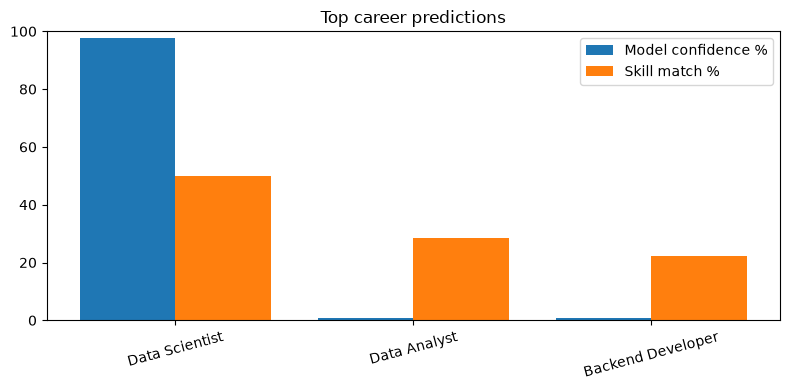

In [9]:
def plot(result):
    names = [r["career"] for r in result["predictions"]]
    conf = [r["confidence"] * 100 for r in result["predictions"]]
    match = [r["match_percent"] for r in result["predictions"]]
    x = range(len(names))
    plt.figure(figsize=(8, 4))
    plt.bar([i - 0.2 for i in x], conf, width=0.4, label="Model confidence %")
    plt.bar([i + 0.2 for i in x], match, width=0.4, label="Skill match %")
    plt.xticks(list(x), names, rotation=15)
    plt.ylim(0, 100)
    plt.legend()
    plt.title("Top career predictions")
    plt.tight_layout()
    plt.show()


plot(result)

### Try your own input

Skills (comma separated):  Data Analyst
Interests (comma separated):  Analyst
Education ['high school', 'diploma', 'bachelors', 'masters', 'phd']:  Bachelors
About you (optional):  


Detected skills: none

=== Frontend Developer  (confidence 17.3%, skill match 0.0%)
  Have   : -
  Missing: html, css, javascript, react, typescript, git, responsive design
  Phase 1 (~4 weeks): html, css
     - Search 'html tutorial for beginners' and build one mini project using html
     - Search 'css tutorial for beginners' and build one mini project using css
  Phase 2 (~4 weeks): javascript, react
     - Search 'javascript tutorial for beginners' and build one mini project using javascript
     - react.dev Learn section; build a to-do app
  Phase 3 (~4 weeks): typescript, git
     - Search 'typescript tutorial for beginners' and build one mini project using typescript
     - Pro Git book (free), chapters 1-3
  Phase 4 (~2 weeks): responsive design
     - Search 'responsive design tutorial for beginners' and build one mini project using responsive design

=== Cybersecurity Analyst  (confidence 13.3%, skill match 0.0%)
  Have   : -
  Missing: networking, linux, python, cryptography

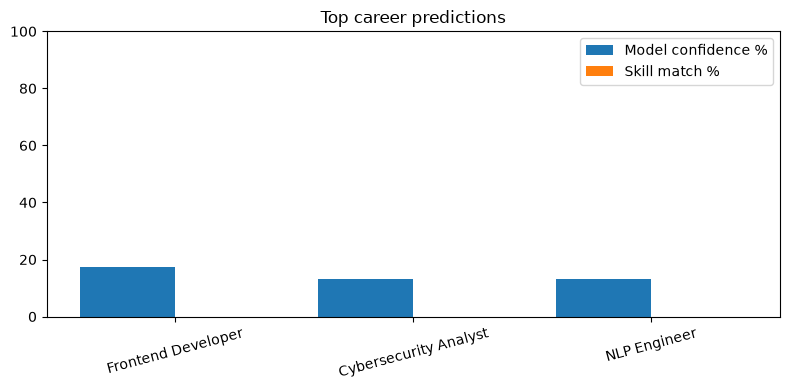

In [10]:
my_skills = input("Skills (comma separated): ")
my_interests = input("Interests (comma separated): ")
my_edu = input(f"Education {EDUCATION_LEVELS}: ") or "bachelors"
my_about = inp
ut("About you (optional): ")

res = recommend([s for s in my_skills.split(",") if s.strip()],
                [i.strip() for i in my_interests.split(",") if i.strip()],
                my_edu, my_about)
show(res)
plot(res)

#FastAPI REST API inside the notebook


In [11]:
from typing import List
from fastapi import FastAPI, HTTPException
from fastapi.testclient import TestClient
from pydantic import BaseModel, Field


class PredictRequest(BaseModel):
    skills: List[str] = Field(default_factory=list)
    interests: List[str] = Field(default_factory=list)
    education: str = "bachelors"
    about: str = ""
    top_k: int = Field(3, ge=1, le=5)


api = FastAPI(title="AI Career Path Predictor")


@api.get("/health")
def health():
    return {"status": "ok", "careers": list(CAREERS)}


@api.post("/predict")
def predict(req: PredictRequest):
    try:
        return recommend(req.skills, req.interests, req.education, req.about, req.top_k)
    except ValueError as e:
        raise HTTPException(400, str(e))


client = TestClient(api)
print(client.get("/health").json())
resp = client.post("/predict", json={"skills": ["html", "css", "js"], "interests": ["design"]})
print(resp.status_code)
show(resp.json())

C:\Users\shreya\anaconda3\Lib\site-packages\fastapi\testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


{'status': 'ok', 'careers': ['Data Scientist', 'Machine Learning Engineer', 'Data Analyst', 'Backend Developer', 'Frontend Developer', 'Full Stack Developer', 'DevOps Engineer', 'Cybersecurity Analyst', 'NLP Engineer']}
200
Detected skills: css, html, javascript

=== Frontend Developer  (confidence 93.2%, skill match 42.9%)
  Have   : html, css, javascript
  Missing: react, typescript, git, responsive design
  Phase 1 (~4 weeks): react, typescript
     - react.dev Learn section; build a to-do app
     - Search 'typescript tutorial for beginners' and build one mini project using typescript
  Phase 2 (~4 weeks): git, responsive design
     - Pro Git book (free), chapters 1-3
     - Search 'responsive design tutorial for beginners' and build one mini project using responsive design

=== Full Stack Developer  (confidence 5.1%, skill match 33.3%)
  Have   : javascript, html, css
  Missing: react, node js, sql, mongodb, rest api, git
  Phase 1 (~4 weeks): react, node js
     - react.dev Lear

In [12]:
# Starts a live server in the background. Re-running this cell may fail if the port is busy.
import threading
import nest_asyncio
import uvicorn

nest_asyncio.apply()
server = uvicorn.Server(uvicorn.Config(api, host="127.0.0.1", port=8000, log_level="warning"))
threading.Thread(target=server.run, daemon=True).start()
print("API running at http://127.0.0.1:8000/docs")
# To stop it later:  server.should_exit = True

API running at http://127.0.0.1:8000/docs
